# K-Means: baseline RFM và PCA — Online Retail

## import thư viện

In [27]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

## Đọc file

In [28]:
path = "../../data/feature/customer_pca.csv"
df = pd.read_csv(path, dtype={"CustomerID": "string"})

X = df.drop(columns="CustomerID")
df.head()

,CustomerID,PC1,PC2
0,12347,2.496214,-0.668303
1,12348,0.388737,0.677161
2,12349,0.094336,-0.554562
3,12350,-1.742704,0.657891
4,12352,1.073803,0.388215


## lựa chọn K tốt nhất

In [29]:
results = []
for k in range(2, min(10, len(X) - 1) + 1):
    model = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = model.fit_predict(X)
    results.append({
        'k': k,
        'Silhouette': silhouette_score(X, labels),
        'DBI': davies_bouldin_score(X, labels),
        'CHI': calinski_harabasz_score(X, labels),
        'Inertia': model.inertia_
    })
metrics = pd.DataFrame(results)
display(metrics.round(4))


,k,Silhouette,DBI,CHI,Inertia
0,2,0.4639,0.8203,4985.9490,5668.3532
1,3,0.3750,0.9472,4303.4035,4080.6451
2,4,0.3786,0.8984,4135.3729,3153.3842
3,5,0.3662,0.8670,4135.4988,2527.8684
4,6,0.3703,0.8641,4135.7620,2109.2378
5,7,0.3728,0.8285,4149.1052,1804.4720
6,8,0.3709,0.8314,4089.1444,1599.8854
7,9,0.3659,0.8477,4057.2063,1432.8826
8,10,0.3596,0.8250,3987.9681,1310.2576


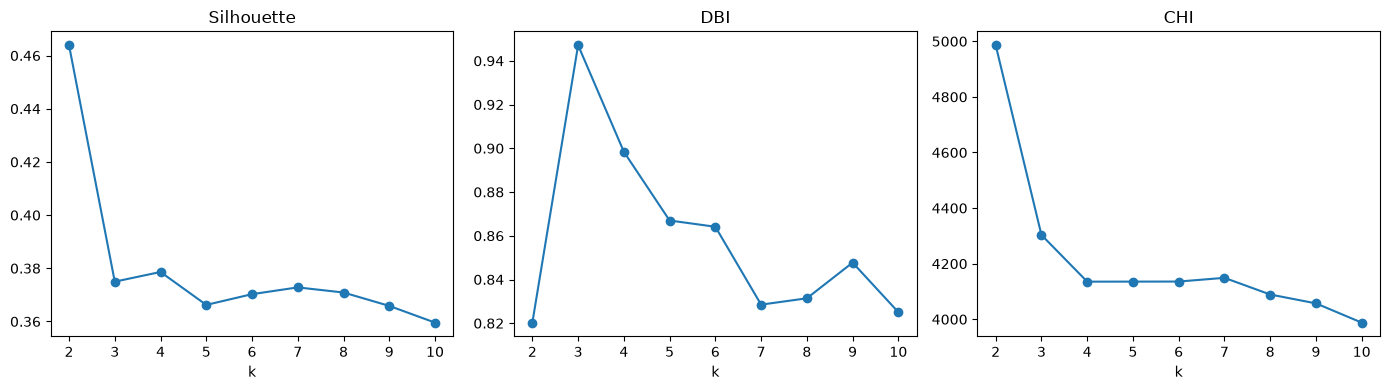

K được đề xuất theo Silhouette: 2


In [30]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ['Silhouette','DBI','CHI']):
    ax.plot(metrics['k'], metrics[col], marker='o')
    ax.set_xlabel('k')
    ax.set_title(col)
plt.tight_layout()
plt.show()

best_k = int(metrics.loc[metrics['Silhouette'].idxmax(), 'k'])
print('K được đề xuất theo Silhouette:', best_k)

## phân cụm

In [31]:
best_model = KMeans(n_clusters=best_k, n_init=20, random_state=42)
cluster_labels = best_model.fit_predict(X)
df["Cluster"] = cluster_labels
display(df.groupby("Cluster").size().rename("Số khách"))

Cluster
0    2667
1    1660
Name: Số khách, dtype: int64

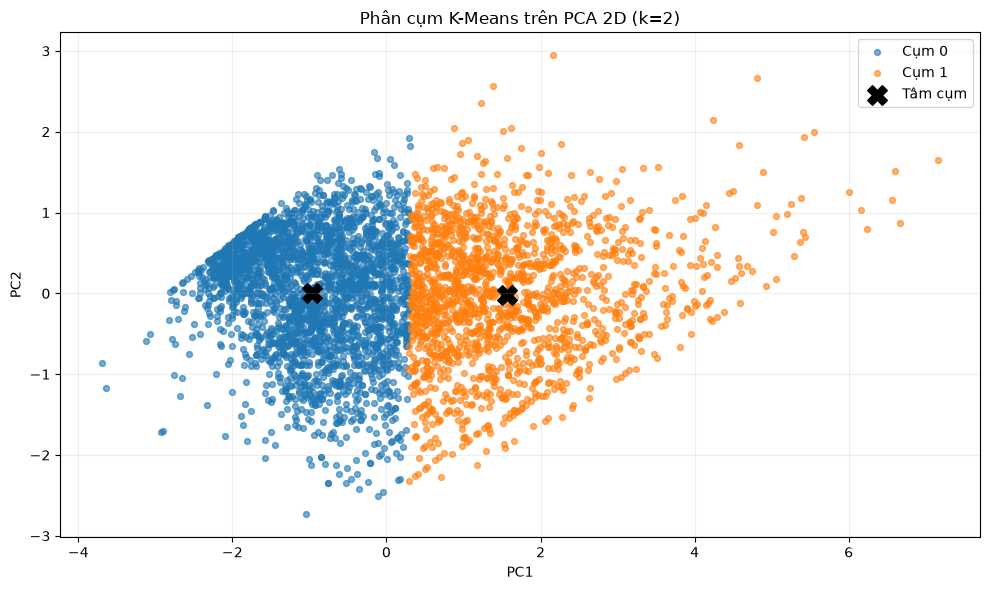

In [32]:
plt.figure(figsize=(10, 6))

for cluster in sorted(np.unique(cluster_labels)):
    mask = cluster_labels == cluster

    plt.scatter(
        X.loc[mask, "PC1"],
        X.loc[mask, "PC2"],
        s=18,
        alpha=0.6,
        label=f"Cụm {cluster}"
    )

# Tâm cụm trong không gian PCA
centers = best_model.cluster_centers_
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=200,
    c="black",
    label="Tâm cụm"
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(f"Phân cụm K-Means trên PCA 2D (k={best_k})")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## RFM trung bình theo cụm

In [33]:
rfm = pd.read_csv("../../data/feature/customer_features.csv",
                  dtype={"CustomerID": "string"})

# Ghép nhãn cụm với RFM gốc bằng mã khách hàng
rfm_cluster = df[["CustomerID", "Cluster"]].merge(
    rfm[["CustomerID", "Recency", "Frequency", "Monetary"]],
    on="CustomerID", validate="one_to_one"
)

summary = rfm_cluster.groupby("Cluster").agg(
    So_khach=("CustomerID", "count"),
    Recency=("Recency", "mean"),
    Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean")
)
display(summary.round(2))

,So_khach,Recency,Frequency,Monetary
Cluster,,,,
0,2667,134.70,1.66,487.06
1,1660,26.11,8.40,4287.22


* nhóm 0: Khách hàng giá trị thấp Recency cao, Frequency thấp và Monetary thấp. Điều này cho thấy họ đã lâu không mua hàng, mua không thường xuyên và có giá trị chi tiêu thấp.
* nhóm 1 : Khách hàng giá trị cao Recency thấp, Frequency cao và Monetary cao cho thấy họ mua hàng gần đây, mua thường xuyên và có giá trị chi tiêu lớn.

## So sánh baseline và PCA


In [ ]:
from sklearn.preprocessing import StandardScaler

X_rfm = rfm_cluster[["Recency", "Frequency", "Monetary"]]
X_rfm_scaled = StandardScaler().fit_transform(np.log1p(X_rfm))

baseline = KMeans(n_clusters=best_k, n_init=20, random_state=42)
labels_baseline = baseline.fit_predict(X_rfm_scaled)


comparison = pd.DataFrame({
    "Cách phân cụm": ["Baseline RFM", "PCA"],
    "Số cụm": [best_k, best_k],
    "Silhouette trên RFM": [
        silhouette_score(X_rfm_scaled, labels_baseline),
        silhouette_score(X_rfm_scaled, rfm_cluster["Cluster"])
    ]
})
display(comparison.round(4))

,Cách phân cụm,Số cụm,Silhouette trên RFM
0,Baseline RFM,2,0.4330
1,PCA,2,0.4329


Silhouette cao hơn nghĩa là các cụm tách biệt hơn theo tiêu chí này trong không gian RFM.
Cần xem thêm bảng RFM để nhận xét nhóm khách hàng, chưa kết luận chỉ từ một chỉ số.

## Vẽ phân cụm baseline
Baseline được phân cụm bằng 3 biến RFM đã chuẩn hóa. Dùng PC1–PC2 để hiển thị kết quả 2D; nhãn màu lấy từ baseline. Số nhãn cụm của hai mô hình không nhất thiết tương ứng nhau.